# Training YOLOv8 — Final Project Oprec PENSHIP

Notebook dasar untuk melatih model deteksi `bottle`, `laptop`, dan `pencil` di Google Colab.
Jalankan cell dari atas ke bawah (**Shift + Enter**). Kode ini sengaja dibuat dasar dan **wajib dikembangkan oleh peserta** (lihat bagian Pengembangan kode di guidebook).

## 1. Aktifkan GPU

Menu **Runtime → Change runtime type → T4 GPU → Save**, lalu jalankan cell di bawah.
Apabila muncul tabel berisi nama GPU (misalnya Tesla T4), GPU sudah aktif.

In [2]:
!nvidia-smi

Sat Oct 24 18:05:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 615.78.05              KMD Version: 617.42        CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 2050        On  |   00000000:01:00.0 Off |                  N/A |
| N/A   54C    P8              5W /   50W |     255MiB /   4096MiB |      3%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install library

In [3]:
%pip install -q "ultralytics>=8.3.0" "roboflow>=1.1.0"


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 3. API key Roboflow

Simpan API key di **Colab Secrets**, jangan diketik di notebook (notebook ini ikut dikumpulkan):

1. Ambil API key di https://app.roboflow.com/settings/api
2. Klik ikon kunci (**Secrets**) di panel kiri Colab → **Add new secret**.
3. Name: `ROBOFLOW_API_KEY`, Value: API key Roboflow, lalu aktifkan **Notebook access**.

Apabila secret tidak ditemukan, cell di bawah akan meminta API key lewat kotak input tersembunyi.

In [4]:
import os

if not os.environ.get("ROBOFLOW_API_KEY"):
    try:
        from google.colab import userdata
        os.environ["ROBOFLOW_API_KEY"] = userdata.get("ROBOFLOW_API_KEY")
    except Exception:
        from getpass import getpass
        os.environ["ROBOFLOW_API_KEY"] = getpass("Roboflow API key: ")

print("API key is set.")

API key is set.


## 4. Konfigurasi

Workspace, project, dan nomor versi tertera pada URL dataset: `app.roboflow.com/<workspace>/<project>/<version>`,
atau di potongan kode saat **Download Dataset → YOLOv8 → Show download code**.

In [5]:
# Dataset (Roboflow)
ROBOFLOW_WORKSPACE = "skyblues-workspace-7pe8m"
ROBOFLOW_PROJECT = "object-detection-f29qk"
ROBOFLOW_VERSION = 1
DATASET_DIR = "dataset"

# Training
MODEL = "yolov8n.pt"
EPOCHS = 50
IMGSZ = 640
BATCH = 16
SEED = 0

## 5. Download dataset

Apabila folder `dataset/` sudah berisi `data.yaml`, download dilewati.

In [6]:
from pathlib import Path

data_yaml = Path(DATASET_DIR) / "data.yaml"
if data_yaml.exists():
    print(f"Dataset already exists, skipping download: {data_yaml}")
else:
    from roboflow import Roboflow

    rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])
    version = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT).version(ROBOFLOW_VERSION)
    dataset = version.download("yolov8", location=DATASET_DIR)
    data_yaml = Path(dataset.location) / "data.yaml"

print(data_yaml.read_text())

Dataset already exists, skipping download: dataset/data.yaml
names:
- Pensil
- botol plastik
- laptop
nc: 3
roboflow:
  license: CC BY 4.0
  project: object-detection-f29qk
  url: https://universe.roboflow.com/skyblues-workspace-7pe8m/object-detection-f29qk/dataset/1
  version: 1
  workspace: skyblues-workspace-7pe8m
test: ../test/images
train: ../train/images
val: ../valid/images



In [7]:
%pip install ultralytics


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 6. Training

Dengan T4 GPU dan beberapa ratus foto, 50 epoch biasanya selesai dalam hitungan menit sampai sekitar setengah jam.

In [8]:
from ultralytics import YOLO

model = YOLO(MODEL)  # pretrained weights are downloaded automatically
model.train(data=str(data_yaml), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, seed=SEED)

save_dir = Path(model.trainer.save_dir)
best_path = save_dir / "weights" / "best.pt"
print(f"Training output: {save_dir}")
print(f"Best model     : {best_path}")

Ultralytics 8.4.185 🚀 Python-3.14.4 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimi

## 7. Lihat grafik hasil training

results.png


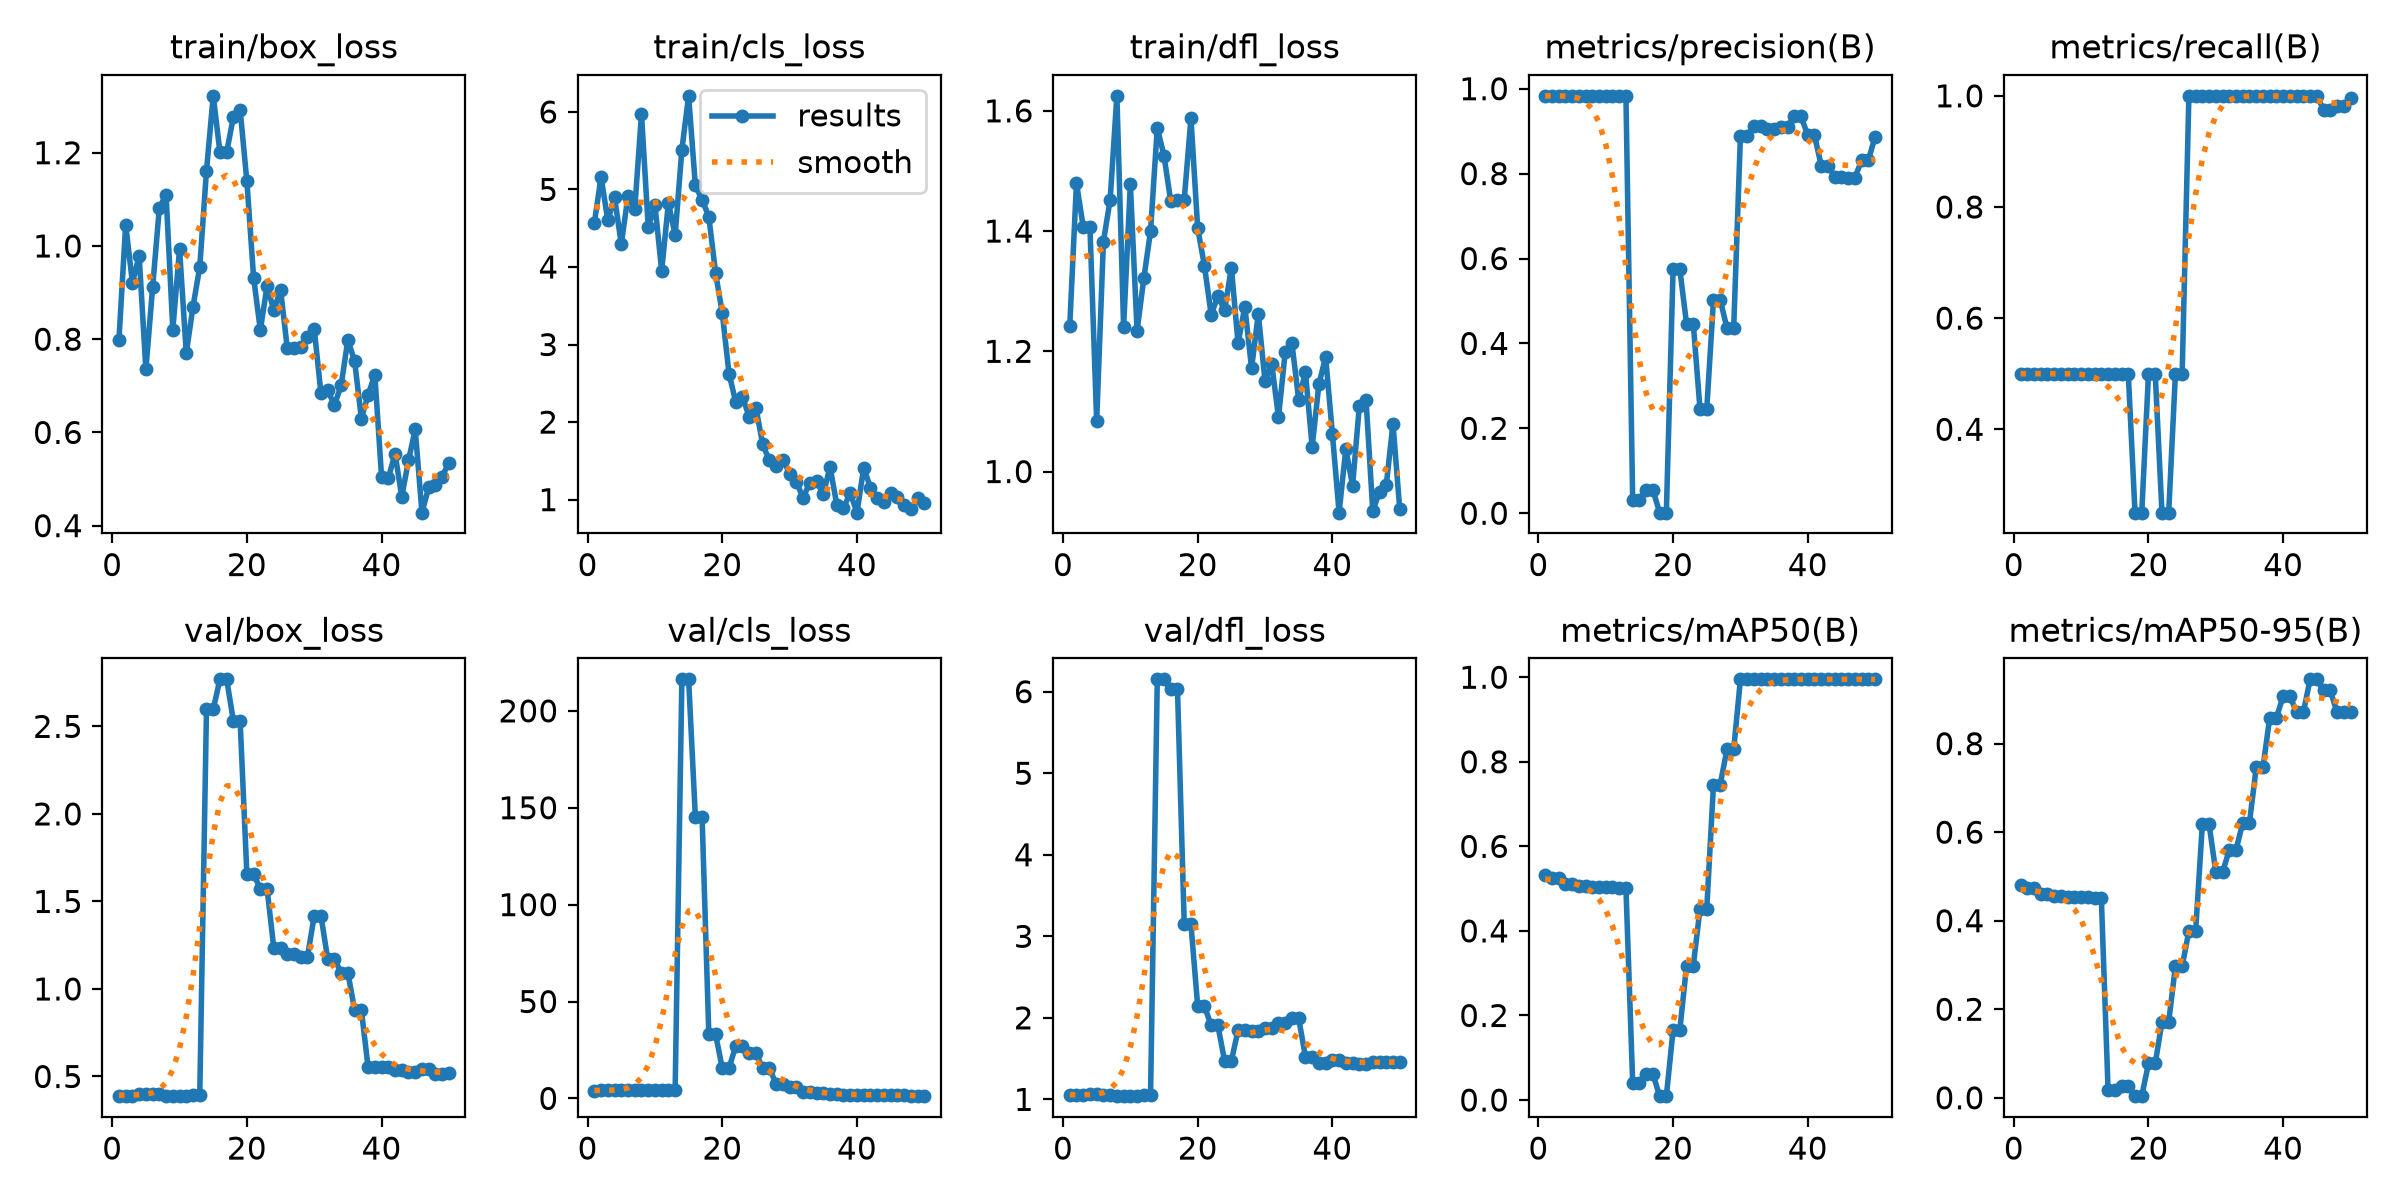

confusion_matrix.png


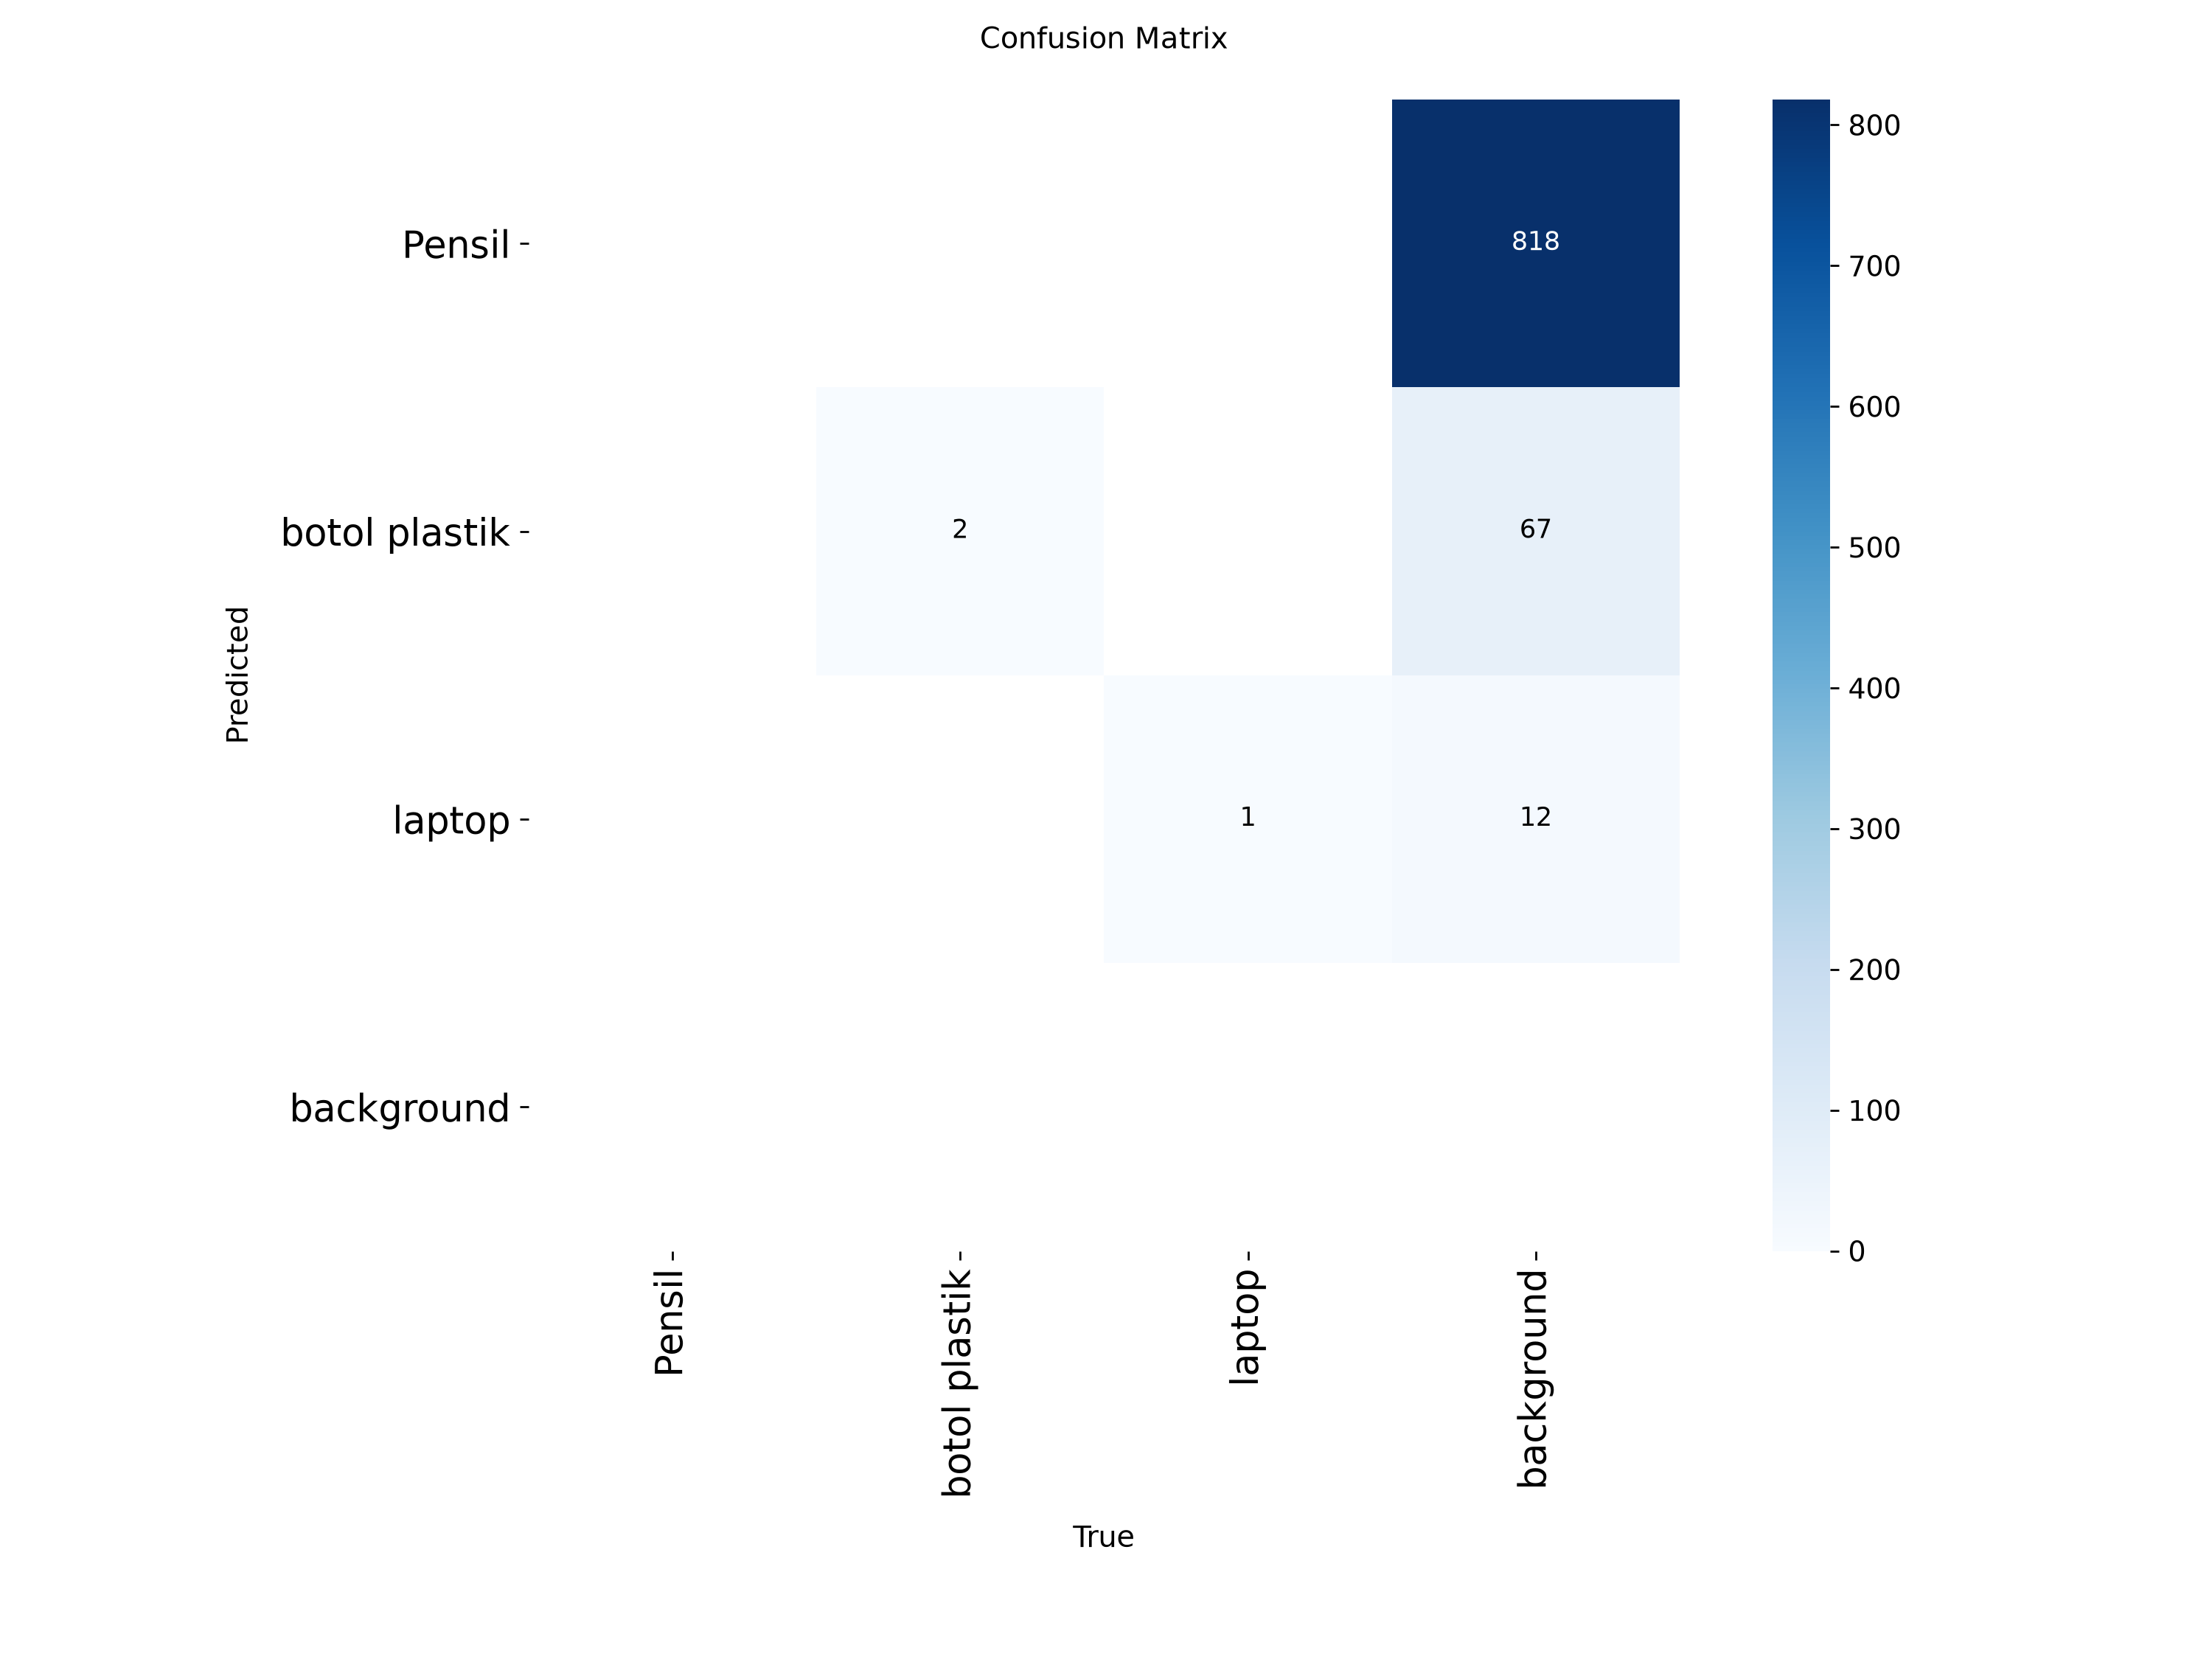

In [9]:
from IPython.display import Image, display

for name in ["results.png", "confusion_matrix.png"]:
    path = save_dir / name
    if path.exists():
        print(name)
        display(Image(filename=str(path), width=900))

## 8. Evaluasi model terbaik di data validation

In [10]:
best_model = YOLO(str(best_path))
metrics = best_model.val(data=str(data_yaml), imgsz=IMGSZ)
print(f"mAP50-95: {metrics.box.map:.3f} | mAP50: {metrics.box.map50:.3f}")

Ultralytics 8.4.185 🚀 Python-3.14.4 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2282.7±224.2 MB/s, size: 32.0 KB)
val: Scanning /home/rizzz/Pytorch/FP_Moch-Salman-Al-Fariz_5225600107/dataset/valid/labels.cache... 3 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3/3 1.4Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 1, len(boxes) = 3. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 8.0it/s 0.1s
                   all          3          3      0.792          1      0.995      0.945
         botol plastik          2          2      0.994          1      0.995      0.9

## 9. Coba prediksi beberapa foto validation


0: 640x640 1 botol plastik, 76.7ms
1: 640x640 1 botol plastik, 76.7ms
2: 640x640 1 laptop, 76.7ms
Speed: 7.4ms preprocess, 76.7ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /home/rizzz/Pytorch/runs/detect/predict
Prediction images saved to: /home/rizzz/Pytorch/runs/detect/predict


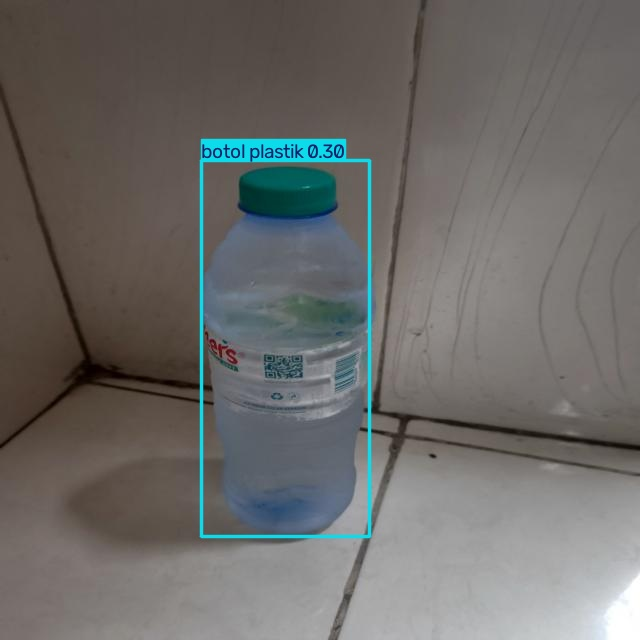

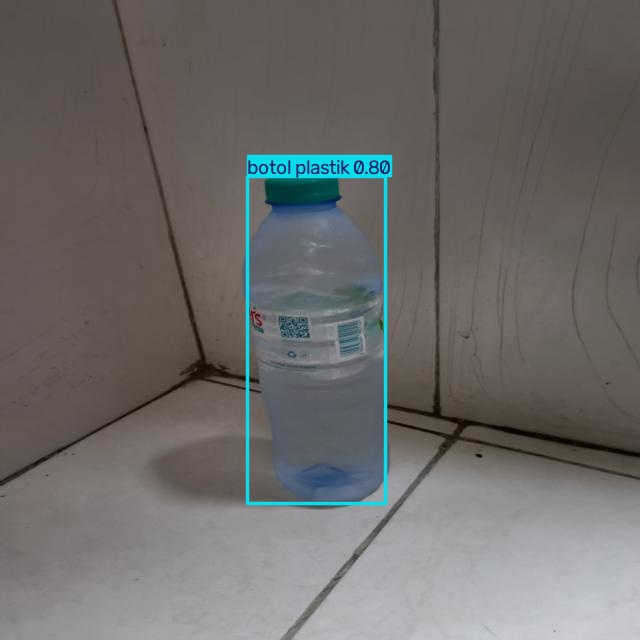

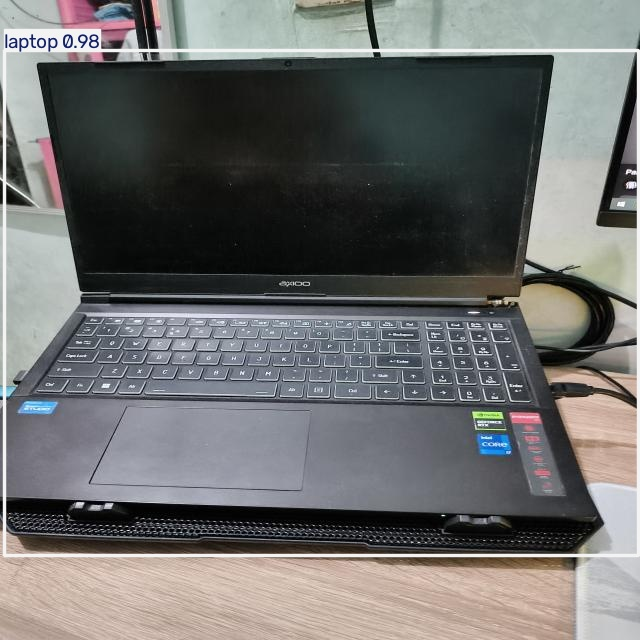

In [13]:
valid_images = sorted((Path(DATASET_DIR) / "valid" / "images").glob("*"))[:4]
results = best_model.predict(source=[str(p) for p in valid_images], imgsz=IMGSZ, conf=0.25, save=True)
print(f"Prediction images saved to: {results[0].save_dir}")

for p in sorted(Path(results[0].save_dir).glob("*.jpg")):
    display(Image(filename=str(p), width=500))

## 10. Simpan hasil sebelum sesi Colab berakhir

File di Colab hilang saat sesi ditutup atau terputus. Cell di bawah membuat `runs.zip` (berisi `best.pt`,
`results.csv`, dan grafik) lalu men-download-nya ke laptop.

In [14]:
import shutil
from pathlib import Path

# Lokasi output training YOLO
runs_dir = Path("/home/rizzz/Pytorch/runs")

# Pastikan foldernya memang ada
print("Folder runs ada:", runs_dir.exists())

if runs_dir.exists():
    zip_path = shutil.make_archive(
        str(Path.cwd() / "runs"),
        "zip",
        root_dir=runs_dir.parent,
        base_dir="runs"
    )
    print(f"Created: {zip_path}")
else:
    print("Folder runs tidak ditemukan. Periksa lokasi output training.")

Folder runs ada: True
Created: /home/rizzz/Pytorch/FP_Moch-Salman-Al-Fariz_5225600107/runs.zip


In [15]:
from pathlib import Path

runs_dir = Path("/home/rizzz/Pytorch/runs/detect/train")

for path in [
    runs_dir / "weights" / "best.pt",
    runs_dir / "weights" / "last.pt",
    runs_dir / "results.png",
    runs_dir / "results.csv",
    runs_dir / "confusion_matrix.png",
    runs_dir / "BoxPR_curve.png",
]:
    print(f"{'ADA' if path.exists() else 'TIDAK ADA'}: {path.name}")

ADA: best.pt
ADA: last.pt
ADA: results.png
ADA: results.csv
ADA: confusion_matrix.png
ADA: BoxPR_curve.png


In [16]:
from pathlib import Path
import shutil

# Folder project submission
project_dir = Path(
    "/home/rizzz/Pytorch/FP_Moch-Salman-Al-Fariz_5225600107"
)

# Lokasi hasil training
train_dir = Path("/home/rizzz/Pytorch/runs/detect/train")
weights_dir = train_dir / "weights"

# Salin best.pt ke root repository
shutil.copy2(weights_dir / "best.pt", project_dir / "best.pt")

# Buat folder grafik
grafik_dir = project_dir / "grafik"
grafik_dir.mkdir(parents=True, exist_ok=True)

# Salin grafik dan data evaluasi
files_to_copy = [
    "results.png",
    "results.csv",
    "confusion_matrix.png",
    "BoxPR_curve.png",
]

for filename in files_to_copy:
    src = train_dir / filename
    if src.exists():
        shutil.copy2(src, grafik_dir / filename)
        print(f"OK: {filename}")
    else:
        print(f"TIDAK DITEMUKAN: {filename}")

print("\nBest model:", project_dir / "best.pt")
print("Folder grafik:", grafik_dir)

OK: results.png
OK: results.csv
OK: confusion_matrix.png
OK: BoxPR_curve.png

Best model: /home/rizzz/Pytorch/FP_Moch-Salman-Al-Fariz_5225600107/best.pt
Folder grafik: /home/rizzz/Pytorch/FP_Moch-Salman-Al-Fariz_5225600107/grafik


In [17]:
import pandas as pd
from pathlib import Path

csv_path = Path("/home/rizzz/Pytorch/runs/detect/train/results.csv")
df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

print("Kolom evaluasi:")
print(df.columns.tolist())

print("\nHasil epoch terakhir:")
print(df.iloc[-1].to_string())

Kolom evaluasi:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']

Hasil epoch terakhir:
epoch                   50.000000
time                    35.774500
train/box_loss           0.535230
train/cls_loss           0.953520
train/dfl_loss           0.938220
metrics/precision(B)     0.887220
metrics/recall(B)        0.995450
metrics/mAP50(B)         0.995000
metrics/mAP50-95(B)      0.870500
val/box_loss             0.519210
val/cls_loss             1.158480
val/dfl_loss             1.458150
lr/pg0                   0.000043
lr/pg1                   0.000043
lr/pg2                   0.000043


In [1]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="0nb1Qioop65bYkAWfdso")
project = rf.workspace("skyblues-workspace-7pe8m").project("object-detection-f29qk")
version = project.version(2)
dataset = version.download("yolov8")
                


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to object-detection-2 in yolov8:: 100%|██████████| 65/65 [00:00<00:00, 4402.22it/s]
